In [1]:
import pandas as pd
import numpy as np

In [9]:
df = pd.read_csv('ShopSmart_data_hcl.csv')

In [10]:
print("\n--- Dataset Dimensions (Rows, Columns) ---")
print(df.shape)
print("\n--- Overview of the Data ---")
df.info()


--- Dataset Dimensions (Rows, Columns) ---
(2000, 9)

--- Overview of the Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 2000 non-null   int64  
 1   Annual_Income       1984 non-null   float64
 2   Website_Visits      1984 non-null   float64
 3   Previous_Purchases  2000 non-null   int64  
 4   Membership_Type     1984 non-null   object 
 5   Preferred_Category  1984 non-null   object 
 6   City_Tier           2000 non-null   object 
 7   Discount_Used       2000 non-null   object 
 8   Amount_Spent        2000 non-null   float64
dtypes: float64(3), int64(2), object(4)
memory usage: 140.8+ KB


In [12]:
df.isnull().sum()

,0
Age,0
Annual_Income,16
Website_Visits,16
Previous_Purchases,0
Membership_Type,16
Preferred_Category,16
City_Tier,0
Discount_Used,0
Amount_Spent,0


In [13]:
df.sample(10)

,Age,Annual_Income,Website_Visits,Previous_Purchases,Membership_Type,Preferred_Category,City_Tier,Discount_Used,Amount_Spent
51,50,405532.0,10.0,6,Bronze,Fashion,Tier 2,Yes,12500.00
1572,46,846987.0,5.0,6,Silver,Home,Tier 2,Yes,18777.82
307,60,749718.0,16.0,6,Bronze,Fashion,Tier 1,No,17028.59
1104,26,726341.0,10.0,7,Bronze,Home,Tier 2,Yes,15599.43
1909,48,329928.0,14.0,0,Silver,Home,Tier 3,Yes,10150.90
1264,41,609652.0,7.0,8,Gold,Fashion,Tier 2,No,16906.64
173,25,407784.0,8.0,4,Bronze,Electronics,Tier 2,Yes,12543.64
638,50,930673.0,8.0,9,Silver,Home,Tier 1,No,21185.48
1552,34,1033399.0,12.0,7,Gold,NaN,Tier 2,Yes,23562.59
722,18,263778.0,10.0,5,Bronze,Home,Tier 3,No,8062.73


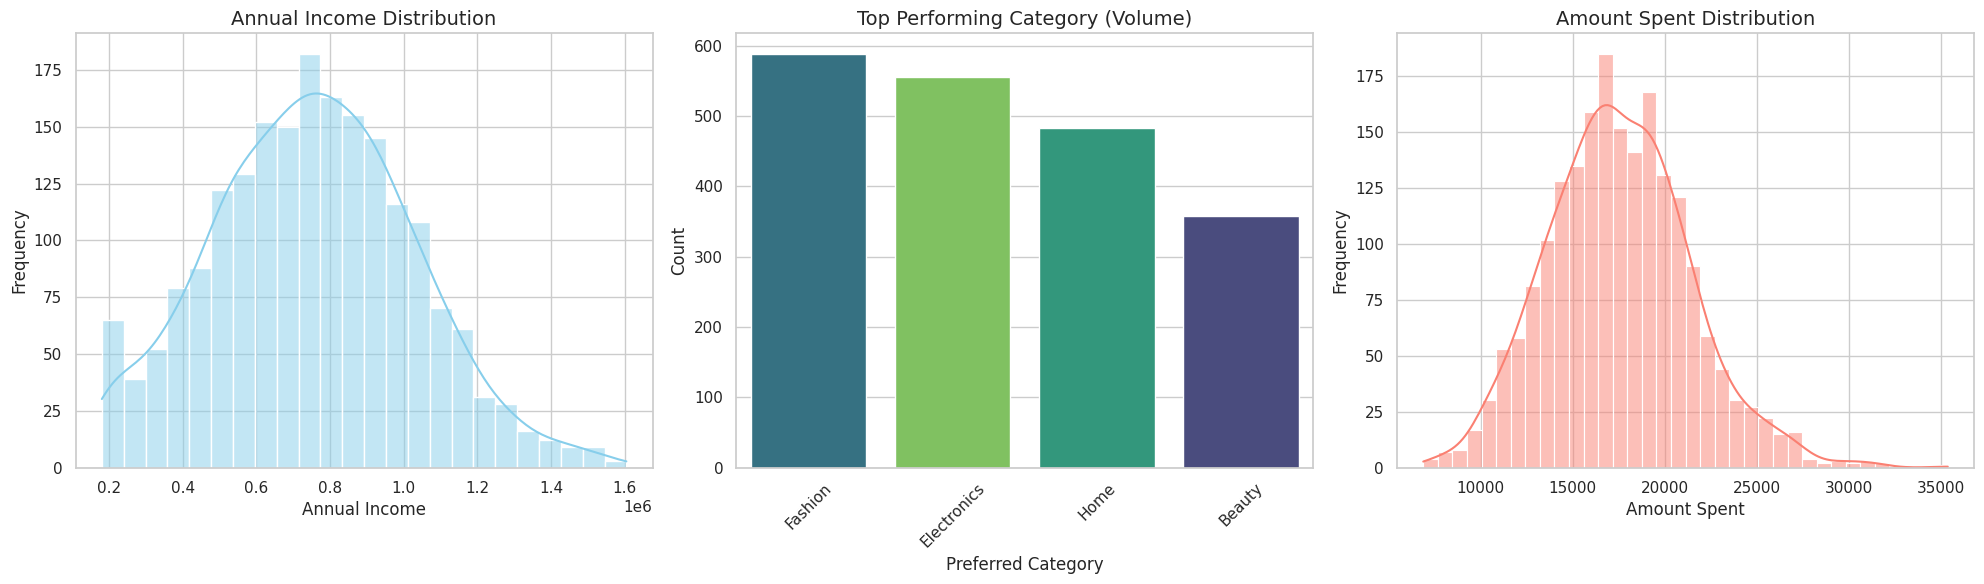

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style for the plots
sns.set_theme(style="whitegrid")

# Create a multi-plot figure
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot 1: Annual Income Distribution
sns.histplot(df['Annual_Income'].dropna(), kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Annual Income Distribution', fontsize=14)
axes[0].set_xlabel('Annual Income', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)

# Plot 2: Top Performing Category (Frequency of Preferred Category)
sns.countplot(data=df, x='Preferred_Category', hue='Preferred_Category', ax=axes[1], palette='viridis', order=df['Preferred_Category'].value_counts().index, legend=False)
axes[1].set_title('Top Performing Category (Volume)', fontsize=14)
axes[1].set_xlabel('Preferred Category', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)

# Plot 3: Amount Spent Distribution
sns.histplot(df['Amount_Spent'], kde=True, ax=axes[2], color='salmon')
axes[2].set_title('Amount Spent Distribution', fontsize=14)
axes[2].set_xlabel('Amount Spent', fontsize=12)
axes[2].set_ylabel('Frequency', fontsize=12)

plt.tight_layout()
plt.show()

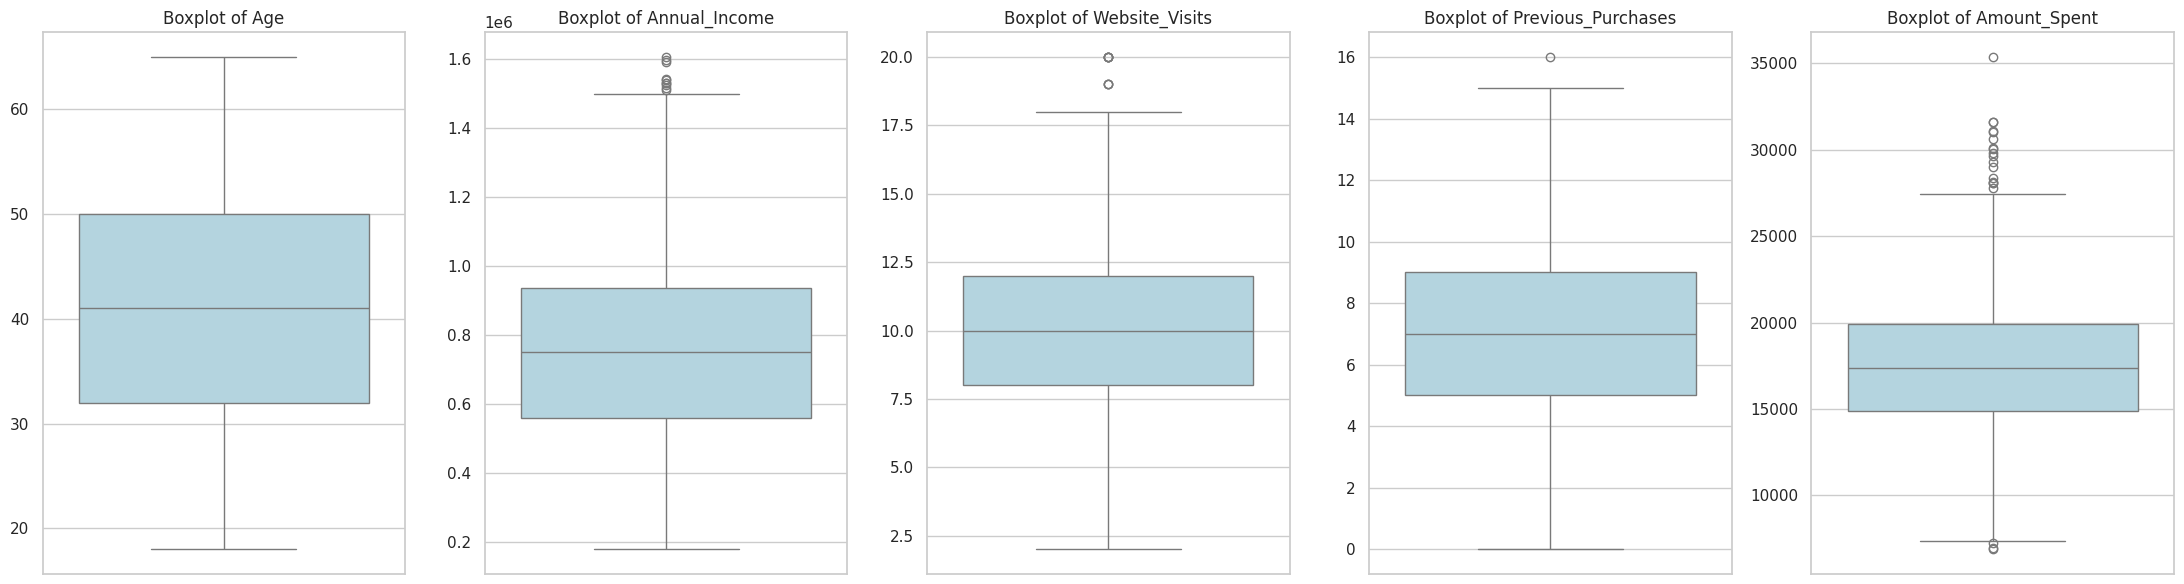

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns for outlier detection
num_cols = ['Age', 'Annual_Income', 'Website_Visits', 'Previous_Purchases', 'Amount_Spent']

# Create a multi-plot layout
fig, axes = plt.subplots(1, 5, figsize=(22, 6))

# Plot box plots for each numerical feature
for i, col in enumerate(num_cols):
    sns.boxplot(data=df, y=col, ax=axes[i], color='lightblue')
    axes[i].set_title(f'Boxplot of {col}', fontsize=12)
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

In [17]:
# Calculate the number of outliers for each numerical column using the IQR method
num_cols = ['Age', 'Annual_Income', 'Website_Visits', 'Previous_Purchases', 'Amount_Spent']

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col}: {len(outliers)} outliers (Range: [{lower_bound:.2f}, {upper_bound:.2f}])")

Age: 0 outliers (Range: [5.00, 77.00])
Annual_Income: 10 outliers (Range: [-6832.38, 1503686.62])
Website_Visits: 8 outliers (Range: [2.00, 18.00])
Previous_Purchases: 1 outliers (Range: [-1.00, 15.00])
Amount_Spent: 20 outliers (Range: [7270.07, 27521.67])


In [19]:
# Fill numeric columns with their median
df['Annual_Income'] = df['Annual_Income'].fillna(df['Annual_Income'].median())
df['Website_Visits'] = df['Website_Visits'].fillna(df['Website_Visits'].median())

# Fill categorical columns with their mode (most frequent value)
df['Membership_Type'] = df['Membership_Type'].fillna(df['Membership_Type'].mode()[0])
df['Preferred_Category'] = df['Preferred_Category'].fillna(df['Preferred_Category'].mode()[0])

# Verify if any missing values remain
print("Remaining missing values:")
print(df.isnull().sum())

Remaining missing values:
Age                   0
Annual_Income         0
Website_Visits        0
Previous_Purchases    0
Membership_Type       0
Preferred_Category    0
City_Tier             0
Discount_Used         0
Amount_Spent          0
dtype: int64


In [20]:
# Export the cleaned DataFrame to a CSV file
df.to_csv('cleaned_data.csv', index=False)
print("Cleaned dataset exported successfully as 'cleaned_data.csv'!")

Cleaned dataset exported successfully as 'cleaned_data.csv'!
